# Advanced Machine Learning 2026/2027
## Project: Modeling Recovery after Lower-Limb Musculoskeletal Injury
### M6 — Reinforcement Learning

**Group:** 14

| Number | Name |
|---|---|
| fc68043 | David Belykh |
| fc68080 | Matilde Quitério |
| fc68091 | Ramyad Raadi |

### Statement on the use of generative AI
The generative AI tool **Claude (Anthropic)** was used in this milestone to support code generation, notebook structuring, debugging and the drafting of written explanations. All code was executed by the group, and every modelling decision, numerical result, interpretation and conclusion was reviewed and validated by the group members, who are able to explain and justify the submitted content.

## 0. Setup and Data

We view rehabilitation as a sequential decision problem:

* **state** $s_t \in \{$`Limited`, `Recovering`, `Functional`$\}$, the recovery state in week $t$ (available in the synthetic data);
* **action** $a_t \in \{$`Rest/Recovery`, `Light Exercise`, `Standard Therapy`, `Intensive Therapy`$\}$, the intervention applied in week $t$;
* **reward** $r_t$, derived from the weekly `utility`.

The environment is estimated from the historical trajectories of **all 3,000 patients**. Unlike M4/M5, no train/test split is needed here: we do not predict outcomes for unseen patients. Instead we want the most precise estimate of the dynamics, and the policies are then compared inside the simulator built from these estimates.

In [1]:
import warnings
import os
import time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
STATES = ["Limited", "Recovering", "Functional"]
ACTIONS = ["Rest/Recovery", "Light Exercise", "Standard Therapy", "Intensive Therapy"]
ACTION_SHORT = ["Rest", "Light", "Standard", "Intensive"]
N_STATES, N_ACTIONS = len(STATES), len(ACTIONS)
S_IDX = {s: i for i, s in enumerate(STATES)}
A_IDX = {a: i for i, a in enumerate(ACTIONS)}
STATE_COLORS = {"Limited": "#E74C3C", "Recovering": "#F39C12", "Functional": "#27AE60"}
ACTION_COLORS = ["#95A5A6", "#5DADE2", "#2E86C1", "#1B2631"]


def find_file(filename, search_paths=(".", "..", "/mnt/data", "dataset", "../dataset")):
    for base in search_paths:
        if not os.path.exists(base):
            continue
        for root, _, files in os.walk(base):
            if filename in files:
                return os.path.join(root, filename)
    raise FileNotFoundError(f"Could not find {filename}.")


rehab = pd.read_csv(find_file("rehabilitation.csv")).sort_values(["patient_id", "week"]).reset_index(drop=True)
rehab["s"] = rehab["state"].map(S_IDX)
rehab["a"] = rehab["intervention"].map(A_IDX)
rehab["s_next"] = rehab.groupby("patient_id")["s"].shift(-1)

transitions = rehab.dropna(subset=["s_next"]).astype({"s_next": int})
print(f"{rehab['patient_id'].nunique():,} patients x {rehab['week'].nunique()} weeks = {len(rehab):,} patient-weeks")
print(f"Transitions (s_t, a_t, r_t, s_t+1) for weeks 0-12: {len(transitions):,} (13 per patient)")
assert rehab[["s", "a"]].notna().all().all()

3,000 patients x 14 weeks = 42,000 patient-weeks
Transitions (s_t, a_t, r_t, s_t+1) for weeks 0-12: 39,000 (13 per patient)


---
## Task 1: Environment Setup

### 1.1 Transition probabilities $P(s_{t+1} \mid s_t, a_t)$

Each patient contributes 13 transitions $(s_t, a_t, r_t, s_{t+1})$, $t = 0,\dots,12$. We estimate
$$\hat P(s' \mid s, a) = \frac{N(s, a, s')}{N(s, a)}$$
by relative frequencies and store the result in an array of shape $n_{states} \times n_{actions} \times n_{states}$.

,State,Intervention,"N(s,a)",P(-> Limited),P(-> Recovering),P(-> Functional),P(improve),P(stay),P(setback)
0,Limited,Rest/Recovery,3549,0.9045,0.0955,0.0000,0.0955,0.9045,0.0000
1,Limited,Light Exercise,4783,0.8597,0.1403,0.0000,0.1403,0.8597,0.0000
2,Limited,Standard Therapy,4305,0.8156,0.1844,0.0000,0.1844,0.8156,0.0000
3,Limited,Intensive Therapy,898,0.8419,0.1581,0.0000,0.1581,0.8419,0.0000
4,Recovering,Rest/Recovery,1501,0.0293,0.9187,0.0520,0.0520,0.9187,0.0293
5,Recovering,Light Exercise,3815,0.0123,0.9038,0.0839,0.0839,0.9038,0.0123
6,Recovering,Standard Therapy,7084,0.0085,0.8674,0.1241,0.1241,0.8674,0.0085
7,Recovering,Intensive Therapy,4722,0.0053,0.8302,0.1645,0.1645,0.8302,0.0053
8,Functional,Rest/Recovery,1294,0.0000,0.0587,0.9413,0.0000,0.9413,0.0587
9,Functional,Light Exercise,3464,0.0000,0.0341,0.9659,0.0000,0.9659,0.0341


trans_mat shape: (3, 4, 3)


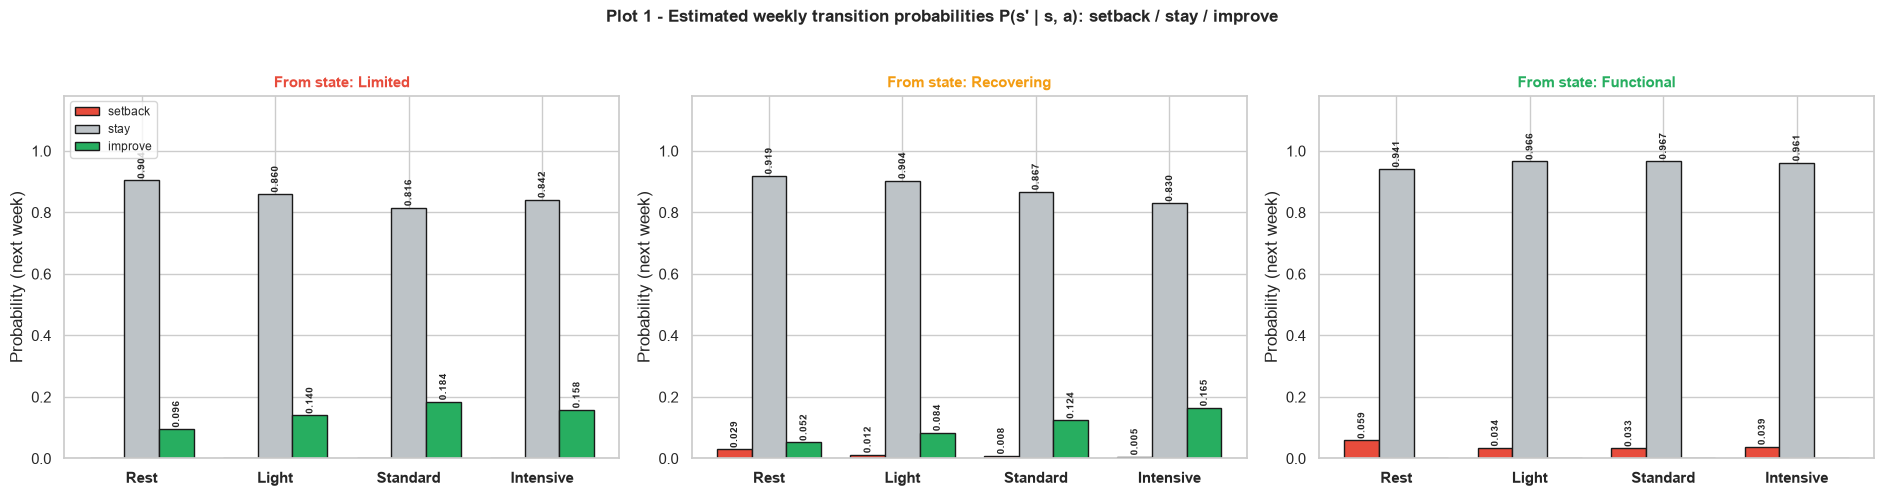

In [2]:
counts = np.zeros((N_STATES, N_ACTIONS, N_STATES))
np.add.at(counts, (transitions["s"].values, transitions["a"].values, transitions["s_next"].values), 1)
n_sa = counts.sum(axis=2)
assert (n_sa > 0).all(), "every (state, action) pair must be observed"
trans_mat = counts / n_sa[:, :, None]
assert trans_mat.shape == (N_STATES, N_ACTIONS, N_STATES) and np.allclose(trans_mat.sum(axis=2), 1)

rows = []
for i, s in enumerate(STATES):
    for j, a in enumerate(ACTIONS):
        p = trans_mat[i, j]
        rows.append({
            "State": s, "Intervention": a, "N(s,a)": int(n_sa[i, j]),
            "P(-> Limited)": p[0], "P(-> Recovering)": p[1], "P(-> Functional)": p[2],
            "P(improve)": p[i + 1:].sum(), "P(stay)": p[i], "P(setback)": p[:i].sum(),
        })
trans_table = pd.DataFrame(rows)
display(trans_table)
print(f"trans_mat shape: {trans_mat.shape}")

# Plot 1: transition probabilities per state and intervention
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for i, s in enumerate(STATES):
    sub = trans_table[trans_table["State"] == s]
    x = np.arange(N_ACTIONS)
    w = 0.26
    for k, (col, lab, colr) in enumerate([("P(setback)", "setback", "#E74C3C"), ("P(stay)", "stay", "#BDC3C7"),
                                           ("P(improve)", "improve", "#27AE60")]):
        vals = sub[col].values
        axes[i].bar(x + (k - 1) * w, vals, w, label=lab, color=colr, edgecolor="k")
        for xi, v in zip(x, vals):
            if v > 0.003:
                axes[i].text(xi + (k - 1) * w, v + 0.012, f"{v:.3f}", ha="center", fontsize=7.5, fontweight="bold", rotation=90)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(ACTION_SHORT, fontweight="bold")
    axes[i].set_ylim(0, 1.18)
    axes[i].set_title(f"From state: {s}", fontsize=11, fontweight="bold", color=STATE_COLORS[s])
    axes[i].set_ylabel("Probability (next week)")
axes[0].legend(loc="upper left", fontsize=8.5)
plt.suptitle("Plot 1 - Estimated weekly transition probabilities P(s' | s, a): setback / stay / improve",
             fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation of the transition probabilities (Plot 1).**

* **Recovery happens one step at a time and is persistent.** In a single week patients only move between neighbouring states: Limited never jumps directly to Functional, and Functional never falls back to Limited. Staying in the same state is by far the most likely outcome (0.82–0.97).
* **Limited:** the probability of improving to Recovering grows with therapy intensity up to Standard Therapy: 0.096 (Rest), 0.140 (Light), **0.184 (Standard)**. Intensive Therapy (0.158) is slightly less effective than Standard. Setbacks are impossible because Limited is already the worst state.
* **Recovering:** more intensive interventions are associated with more progress *and* fewer setbacks. The probability of reaching Functional rises monotonically from 0.052 (Rest) to 0.084, 0.124 and **0.165 (Intensive)**, while the setback risk falls from 0.029 (Rest) to 0.012, 0.0085 and 0.0053. Resting while Recovering more than triples the setback risk compared with Standard Therapy.
* **Functional:** active interventions help to *maintain* recovery. The setback probability is 0.059 with Rest/Recovery, against 0.033–0.039 with Light, Standard or Intensive.

All 12 state–intervention pairs have at least 898 observed transitions, so the estimates are reasonably precise. They are, however, **observational associations**: clinicians chose the interventions, possibly based on patient information that is not part of the state (e.g. Intensive Therapy is used in only 6.6% of Limited weeks). The estimated effects may therefore be confounded.

### 1.2 Reward function $r(s, a) = \mathbb{E}[\text{utility} \mid s, a]$

The expected reward is the average `utility` of all patient-weeks in which intervention $a$ was applied in state $s$. All 14 weeks are used (week 13 also has a state, an intervention and a utility, even though it has no next state). We also show the standard error of each estimate and, for reference, how often the clinicians in the dataset chose each intervention in each state (the **behaviour policy**).

Expected immediate reward r(s, a):


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,-5.9891,-6.2987,-7.3208,-7.4944
Recovering,4.4173,3.9034,2.7728,1.4033
Functional,14.4725,13.7624,12.3913,11.0155


Standard error of r(s, a):


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,0.1179,0.1025,0.1077,0.2299
Recovering,0.1787,0.1113,0.0819,0.0997
Functional,0.1725,0.1059,0.1196,0.2088


Behaviour policy in the data, P(a | s):


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,0.2619,0.3546,0.3178,0.0657
Recovering,0.0867,0.2214,0.4160,0.2759
Functional,0.1531,0.4107,0.3258,0.1104


Immediate-reward-maximising intervention per state: {'Limited': 'Rest/Recovery', 'Recovering': 'Rest/Recovery', 'Functional': 'Rest/Recovery'}
Reward range across interventions within a state: Limited: 1.51, Recovering: 3.01, Functional: 3.46 | range across states (Rest): 20.46


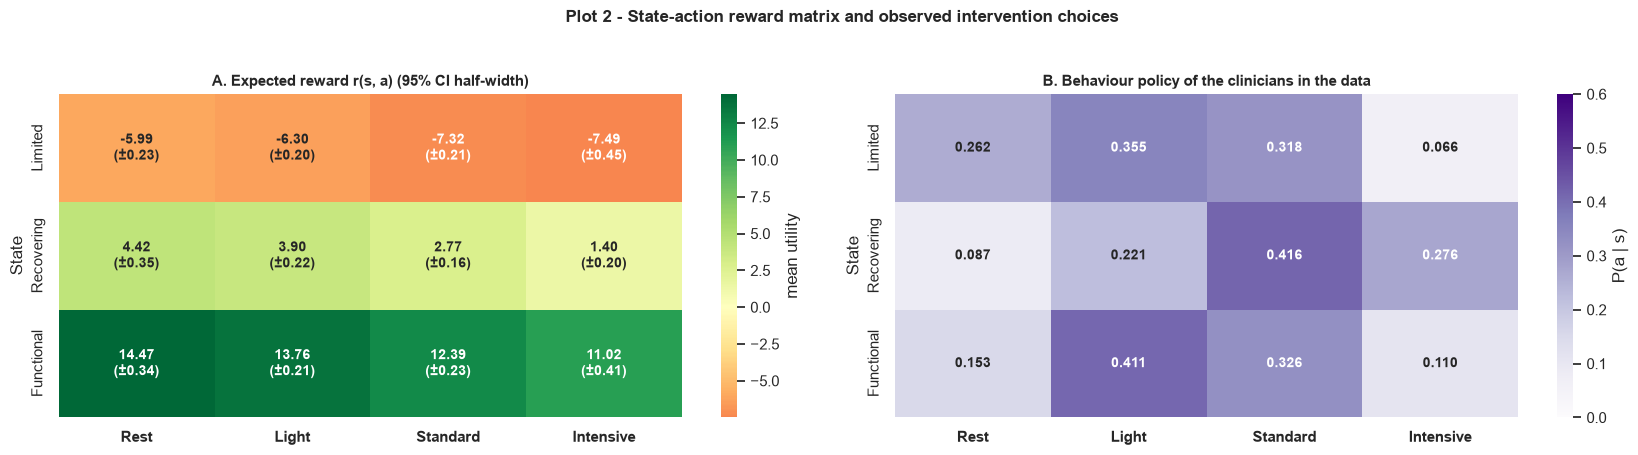

In [3]:
grp = rehab.groupby(["s", "a"])["utility"]
r_sa = grp.mean().unstack().reindex(index=range(N_STATES), columns=range(N_ACTIONS)).values
r_sd = grp.std().unstack().reindex(index=range(N_STATES), columns=range(N_ACTIONS)).values
r_n = grp.size().unstack().reindex(index=range(N_STATES), columns=range(N_ACTIONS)).values
assert r_sa.shape == (N_STATES, N_ACTIONS)

reward_df = pd.DataFrame(r_sa, index=STATES, columns=ACTIONS)
se_df = pd.DataFrame(r_sd / np.sqrt(r_n), index=STATES, columns=ACTIONS)
behav = pd.crosstab(rehab["s"], rehab["a"], normalize="index").reindex(index=range(N_STATES), columns=range(N_ACTIONS)).values
behav_df = pd.DataFrame(behav, index=STATES, columns=ACTIONS)

print("Expected immediate reward r(s, a):")
display(reward_df)
print("Standard error of r(s, a):")
display(se_df)
print("Behaviour policy in the data, P(a | s):")
display(behav_df)
print("Immediate-reward-maximising intervention per state:",
      {s: ACTIONS[int(np.argmax(r_sa[i]))] for i, s in enumerate(STATES)})
print(f"Reward range across interventions within a state: "
      + ", ".join(f"{s}: {r_sa[i].max() - r_sa[i].min():.2f}" for i, s in enumerate(STATES))
      + f" | range across states (Rest): {r_sa[:, 0].max() - r_sa[:, 0].min():.2f}")

# Plot 2
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
annot = np.array([[f"{r_sa[i, j]:.2f}\n(±{1.96 * se_df.values[i, j]:.2f})" for j in range(N_ACTIONS)] for i in range(N_STATES)])
sns.heatmap(reward_df, annot=annot, fmt="", cmap="RdYlGn", center=0, ax=axes[0], annot_kws={"size": 10, "weight": "bold"},
            cbar_kws={"label": "mean utility"})
axes[0].set_title("A. Expected reward r(s, a) (95% CI half-width)", fontsize=11, fontweight="bold")
sns.heatmap(behav_df, annot=True, fmt=".3f", cmap="Purples", vmin=0, vmax=0.6, ax=axes[1],
            annot_kws={"size": 10, "weight": "bold"}, cbar_kws={"label": "P(a | s)"})
axes[1].set_title("B. Behaviour policy of the clinicians in the data", fontsize=11, fontweight="bold")
for ax in axes:
    ax.set_xticklabels(ACTION_SHORT, rotation=0, fontweight="bold")
    ax.set_ylabel("State")
plt.suptitle("Plot 2 - State-action reward matrix and observed intervention choices", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

**Interpretation of the reward matrix (Plot 2).**

* **The recovery state dominates the reward.** Limited weeks have negative utility (−6.0 to −7.5), Recovering weeks are slightly positive (+1.4 to +4.4) and Functional weeks are strongly positive (+11.0 to +14.5). The difference between states (20.5 points for Rest) is much larger than the difference between interventions within a state (1.5 in Limited, 3.0 in Recovering, 3.5 in Functional).
* **Within every state the immediate reward decreases with intensity:** Rest > Light > Standard > Intensive. This reflects the burden of more intensive rehabilitation that is built into `utility`. The standard errors (0.08–0.23) are small compared with these differences. The only exception is Limited, where Standard (−7.32) and Intensive (−7.49) are practically indistinguishable.
* Consequently, an agent that only maximises immediate reward chooses **Rest/Recovery in every state**. The benefit of therapy appears only *indirectly*, through the transition probabilities (Plot 1): therapy makes it more likely to reach a better state, whose rewards are about 10 points higher per week. This is exactly the trade-off between immediate and long-term utility that reinforcement learning has to resolve.
* The clinicians in the data do not behave myopically: they mostly use Light or Standard Therapy in Limited (35% and 32%), Standard or Intensive Therapy in Recovering (42% and 28%), and Light Exercise in Functional (41%).

### 1.3 Initial-state distribution and simulator

The initial-state distribution $\pi$ is estimated from each patient's first rehabilitation week (week 0). We then build the simulator exactly as specified in the assignment, with a horizon of 13 decisions per episode.

In [4]:
pi = rehab.loc[rehab["week"] == 0, "s"].value_counts(normalize=True).reindex(range(N_STATES)).fillna(0).values
display(pd.DataFrame({"pi (week 0)": pi, "count": (pi * rehab["patient_id"].nunique()).round().astype(int)}, index=STATES).T)


# environment simulator for Q-learning (as given in the assignment)
class RehabilitationEnv:
    def __init__(self, pi, P, R, horizon=13, seed=0):
        self.pi = pi
        self.P = P
        self.R = R
        self.horizon = horizon
        self.n_states = P.shape[0]
        self.rng = np.random.default_rng(seed)

    def reset(self):
        self.t = 0
        self.s = int(self.rng.choice(self.n_states, p=self.pi))
        return self.s

    def step(self, a):
        reward = float(self.R[self.s, a])
        s_next = int(self.rng.choice(self.n_states,
                                     p=self.P[self.s, a]))
        self.s = s_next
        self.t += 1
        done = self.t >= self.horizon
        return s_next, reward, done, {}


env = RehabilitationEnv(pi, trans_mat, r_sa)


# --- Generic simulator for any policy (as given in the assignment) ---
def evaluate_policy(env, policy_fn, Q=None, episodes=1000, seed=0):
    rng = np.random.default_rng(seed)
    returns = []
    for _ in range(episodes):
        s = env.reset()
        G = 0.0
        for t in range(env.horizon):
            a = policy_fn(s, Q=Q, rng=rng)
            s, r, done, _ = env.step(a)
            G += r
            if done:
                break
        returns.append(G)
    return np.array(returns)

,Limited,Recovering,Functional
pi (week 0),0.6880,0.3110,0.0010
count,2064.0000,933.0000,3.0000


**Sanity check of the simulator.** If the simulator is a faithful summary of the data, then replaying the clinicians' own behaviour policy $P(a \mid s)$ (Plot 2B) inside it should give returns similar to the observed ones. The observed return of a patient is the sum of the utilities of weeks 0–12 (the same 13 decisions as one episode).

,count,mean,std,min,25%,50%,75%,max
Observed patients (data),3000.0000,21.8093,92.6072,-250.4000,-45.3000,26.7500,92.5000,270.3000
Behaviour policy in simulator,3000.0000,29.2403,72.1834,-92.0060,-29.5832,33.1699,86.8439,166.6488


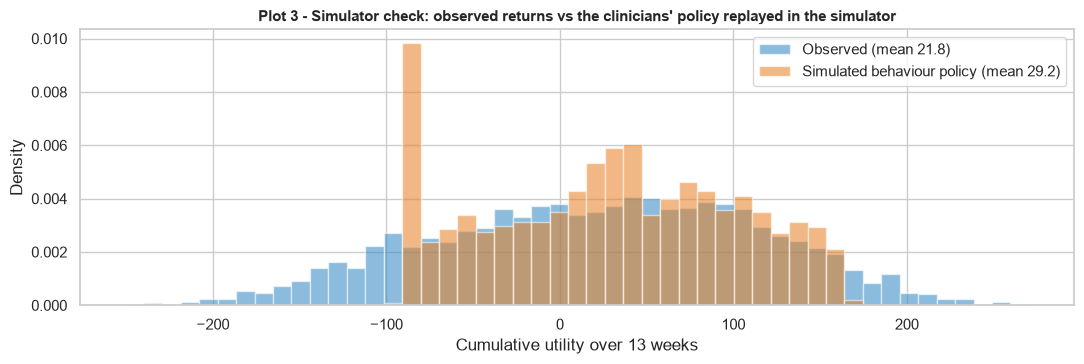

In [5]:
def behaviour_policy(s, Q=None, rng=None):
    return int(rng.choice(N_ACTIONS, p=behav[s]))


observed_returns = rehab[rehab["week"] <= 12].groupby("patient_id")["utility"].sum().values
sim_behaviour = evaluate_policy(RehabilitationEnv(pi, trans_mat, r_sa, seed=RANDOM_STATE), behaviour_policy,
                                episodes=3000, seed=RANDOM_STATE)

check_df = pd.DataFrame({
    "Observed patients (data)": pd.Series(observed_returns).describe(),
    "Behaviour policy in simulator": pd.Series(sim_behaviour).describe(),
}).T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(check_df)

# Plot 3
fig, ax = plt.subplots(figsize=(11, 3.8))
bins = np.linspace(min(observed_returns.min(), sim_behaviour.min()), max(observed_returns.max(), sim_behaviour.max()), 50)
ax.hist(observed_returns, bins=bins, alpha=0.55, color="#2E86C1", label=f"Observed (mean {observed_returns.mean():.1f})", density=True)
ax.hist(sim_behaviour, bins=bins, alpha=0.55, color="#E67E22", label=f"Simulated behaviour policy (mean {sim_behaviour.mean():.1f})", density=True)
ax.set_xlabel("Cumulative utility over 13 weeks")
ax.set_ylabel("Density")
ax.legend()
ax.set_title("Plot 3 - Simulator check: observed returns vs the clinicians' policy replayed in the simulator",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

**Simulator check (Plot 3).** Replaying the clinicians' behaviour policy in the simulator gives returns of the same order of magnitude and a similar shape as the real patients (mean 29.2 vs 21.8, median 33.2 vs 26.8), but the simulator is **more optimistic** (+7.4 on average) and **less variable** (SD 72.2 vs 92.6). Two simplifications explain this:

* the simulator returns the *mean* reward $r(s,a)$, removing the week-to-week noise of `utility` (within-cell SD ≈ 7 per week), which narrows the distribution of returns;
* it is a homogeneous Markov chain in which every patient has the same transition probabilities. In the data, some patients (e.g. high-risk patients) stay in Limited for very long periods. The Markov model averages these patients with faster recoverers, so it underestimates long stays in Limited.

The simulator is therefore a simplified but reasonable approximation of the data. Absolute returns should be interpreted with caution, but comparisons *between policies* inside the same simulator remain meaningful.

---
## Task 2: Tabular Q-learning

### 2.1 Algorithm and hyper-parameters

At every step the agent takes an $\epsilon$-greedy action, observes $(r_t, s_{t+1})$ and applies the off-policy update
$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha\big[r_t + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t)\big],$$
where the bootstrap term is dropped at the last step of the episode (week 12 → end).

| Hyper-parameter | Value | Justification |
|---|---|---|
| Learning rate $\alpha$ | $\alpha_t(s,a) = 1 / N_t(s,a)^{0.7}$, where $N_t(s,a)$ is the number of updates of that pair so far | The next state is random, and the target of the *last* week of an episode has no bootstrap term, so the TD targets of a pair vary a lot. A step size that decreases with the number of visits satisfies the Robbins–Monro conditions ($\sum \alpha = \infty$, $\sum \alpha^2 < \infty$), so the estimates average out this noise and converge. Large steps are still taken early on, when the Q-values are far from their final value. We first tried a constant $\alpha = 0.05$: the Q-values kept fluctuating by several units and the greedy policy changed from seed to seed (Section 2.2). |
| Discount factor $\gamma$ | $0.95$ | An episode lasts 13 weeks and the goal is **long-term** recovery. With $\gamma = 0.95$ a reward 12 weeks ahead still keeps $0.95^{12} \approx 0.54$ of its weight, so the whole rehabilitation period matters, while immediate outcomes are still slightly preferred. Other values are studied in Section 2.4. |
| Exploration $\epsilon$ | linear decay from $1.0$ to $0.05$ over the first 60% of episodes, then fixed at $0.05$ | Early on, every intervention must be tried in every state (there are only 12 state-action pairs). Later the agent mostly exploits, while a residual 5% exploration keeps every Q-value updated. |
| Episodes | $100{,}000$ (1.3 million updates) | Enough for every $(s, a)$ pair to be updated tens of thousands of times, so the small differences between interventions can be resolved. |

Ties in the greedy choice are broken at random.

In [6]:
OMEGA, GAMMA = 0.7, 0.95          # alpha_t(s,a) = 1 / N_t(s,a)**OMEGA
EPS_START, EPS_END, EPS_DECAY_FRAC = 1.0, 0.05, 0.6
N_EPISODES = 100_000


def greedy(q_row, rng):
    best = np.flatnonzero(q_row == q_row.max())
    return int(best[0]) if len(best) == 1 else int(rng.choice(best))


def q_learning(env, n_episodes=N_EPISODES, omega=OMEGA, const_alpha=None, gamma=GAMMA, eps_start=EPS_START,
               eps_end=EPS_END, eps_decay_frac=EPS_DECAY_FRAC, seed=0, snapshot_every=1000):
    """Tabular Q-learning. Step size 1/N(s,a)**omega, or a constant step size if const_alpha is given."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, N_ACTIONS))
    visits = np.zeros((env.n_states, N_ACTIONS), dtype=int)
    visits_t = np.zeros((env.horizon, env.n_states), dtype=int)       # state visits per week of the episode
    ep_returns, snapshots = np.zeros(n_episodes), []
    decay_eps = eps_decay_frac * n_episodes
    for ep in range(n_episodes):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / decay_eps)
        s, G, done = env.reset(), 0.0, False
        while not done:
            a = int(rng.integers(N_ACTIONS)) if rng.random() < eps else greedy(Q[s], rng)
            visits_t[env.t, s] += 1
            s_next, r, done, _ = env.step(a)
            target = r if done else r + gamma * Q[s_next].max()
            visits[s, a] += 1
            alpha = const_alpha if const_alpha is not None else 1.0 / visits[s, a] ** omega
            Q[s, a] += alpha * (target - Q[s, a])
            G += r
            s = s_next
        ep_returns[ep] = G
        if (ep + 1) % snapshot_every == 0:
            snapshots.append(Q.copy())
    return Q, ep_returns, np.array(snapshots), visits, visits_t


t0 = time.perf_counter()
env_train = RehabilitationEnv(pi, trans_mat, r_sa, seed=RANDOM_STATE)
Q, train_returns, Q_snapshots, visits, visits_t = q_learning(env_train, seed=RANDOM_STATE)
print(f"Training: {N_EPISODES:,} episodes in {time.perf_counter() - t0:.1f} s")

q_df = pd.DataFrame(Q, index=STATES, columns=ACTIONS)
policy_q = Q.argmax(axis=1)
print("\nLearned Q-table (gamma = 0.95):")
display(q_df)
print("State-action visit counts during training:")
display(pd.DataFrame(visits, index=STATES, columns=ACTIONS))
print("Greedy policy derived from Q:")
display(pd.DataFrame({
    "Preferred intervention": [ACTIONS[a] for a in policy_q],
    "Q of best": Q.max(axis=1),
    "Margin over 2nd best": np.sort(Q, axis=1)[:, -1] - np.sort(Q, axis=1)[:, -2],
    "Immediate-reward best": [ACTIONS[a] for a in r_sa.argmax(axis=1)],
}, index=STATES))

Training: 100,000 episodes in 9.5 s

Learned Q-table (gamma = 0.95):


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,-0.9741,0.9022,1.7188,-0.1727
Recovering,44.5382,44.6152,45.2957,44.4533
Functional,71.3485,70.2490,68.9454,68.3397


State-action visit counts during training:


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,34638,37708,282908,34583
Recovering,49239,114056,347314,70410
Functional,225146,52023,26110,25865


Greedy policy derived from Q:


,Preferred intervention,Q of best,Margin over 2nd best,Immediate-reward best
Limited,Standard Therapy,1.7188,0.8165,Rest/Recovery
Recovering,Standard Therapy,45.2957,0.6806,Rest/Recovery
Functional,Rest/Recovery,71.3485,1.0995,Rest/Recovery


### 2.2 Convergence, robustness and exact references

We check the learned policy in three ways:

1. **Seeds and learning rate.** Q-learning is repeated with 5 random seeds, with the decreasing step size used above and with a constant $\alpha = 0.05$.
2. **Value iteration.** Because the environment model $(\pi, P, R)$ is known, we can compute the optimal *infinite-horizon* discounted Q-function, $Q^*(s,a) = r(s,a) + \gamma \sum_{s'} P(s' \mid s,a) \max_{a'} Q^*(s',a')$. Q-learning never accesses $P$ or $R$; this is only a reference.
3. **Exact evaluation of all stationary policies.** There are only $4^3 = 64$ deterministic policies that map a recovery state to an intervention. For each one we compute the exact expected undiscounted 13-week return by propagating the state distribution forward, $d_{t+1} = d_t P_\pi$ with $d_0 = \pi$ and $G = \sum_{t=0}^{12} d_t \cdot r_\pi$. This gives the best policy *that only looks at the recovery state* for the objective used in Task 3.

,Step size,Seed,Limited,Recovering,Functional,Smallest margin best vs 2nd,Exact 13-week return
0,1/N^0.7 (used),0,Standard Therapy,Standard Therapy,Rest/Recovery,0.4648,40.4462
1,1/N^0.7 (used),1,Standard Therapy,Intensive Therapy,Rest/Recovery,0.1533,42.6923
2,1/N^0.7 (used),2,Standard Therapy,Intensive Therapy,Rest/Recovery,0.6947,42.6923
3,1/N^0.7 (used),3,Standard Therapy,Standard Therapy,Rest/Recovery,0.2928,40.4462
4,1/N^0.7 (used),4,Standard Therapy,Standard Therapy,Rest/Recovery,0.2717,40.4462
5,constant 0.05,0,Standard Therapy,Light Exercise,Rest/Recovery,0.4141,36.4280
6,constant 0.05,1,Intensive Therapy,Intensive Therapy,Light Exercise,2.2858,35.8398
7,constant 0.05,2,Standard Therapy,Standard Therapy,Rest/Recovery,1.2402,40.4462
8,constant 0.05,3,Standard Therapy,Intensive Therapy,Light Exercise,3.4229,42.8852
9,constant 0.05,4,Intensive Therapy,Standard Therapy,Rest/Recovery,6.8361,33.4823


Value-iteration Q* (gamma = 0.95, infinite horizon):


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Limited,108.3470,111.1892,113.2752,111.2495
Recovering,182.9998,185.2994,186.4773,187.3819
Functional,240.1842,240.7243,239.4135,237.7502


Top 8 of the 64 stationary policies:


,Policy (Limited / Recovering / Functional),Exact 13-week return
Rank,,
1,Standard / Intensive / Light,42.8852
2,Standard / Intensive / Rest,42.6923
3,Standard / Standard / Light,40.4933
4,Standard / Standard / Rest,40.4462
5,Standard / Intensive / Standard,36.8534
6,Standard / Light / Rest,36.4280
7,Standard / Light / Light,36.4038
8,Light / Intensive / Light,36.0143


Q-learning policy      : Standard / Standard / Rest       exact return  40.45  (rank 4/64)
Value-iteration policy : Standard / Intensive / Light     exact return  42.89  (rank 1/64)
Myopic policy (Rest x3): Rest / Rest / Rest               exact return   9.41  (rank 62/64)

Share of each state's visits that happen in the last decision week (week 12) or in weeks 9-12 during training:


,Limited,Recovering,Functional
week 12,0.0255,0.0731,0.1447
weeks 9-12,0.1274,0.3052,0.5256
mean week of visit,3.8447,6.1581,8.2736


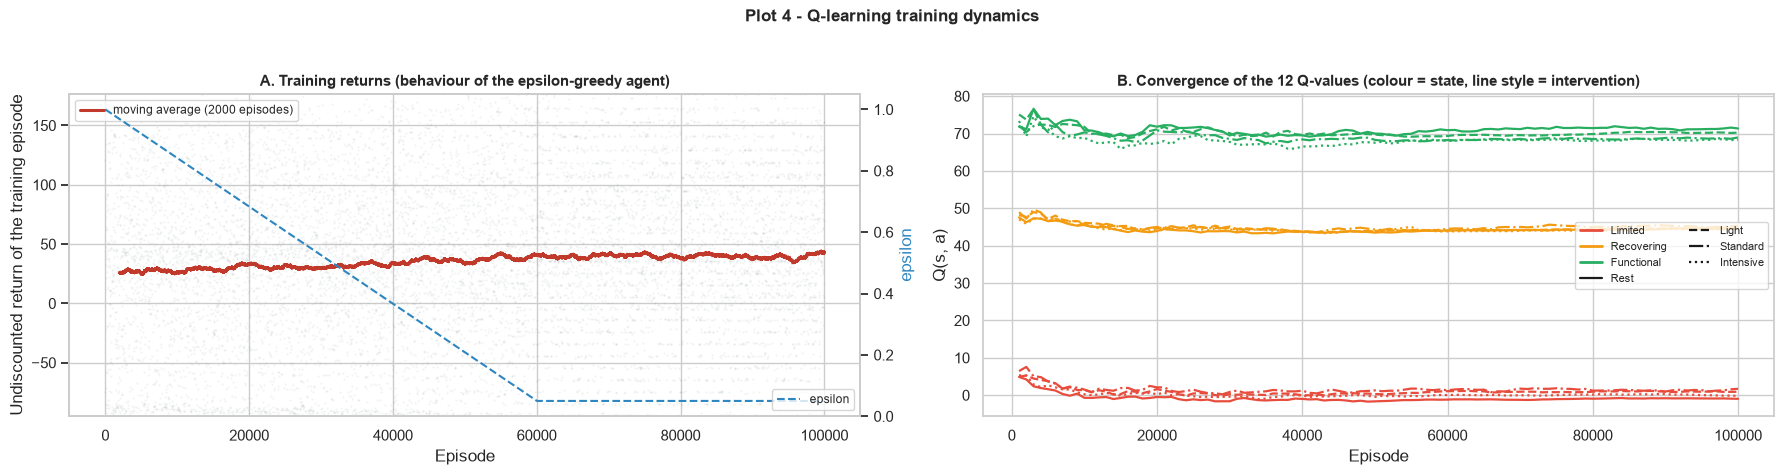

In [7]:
def value_iteration(P, R, gamma, tol=1e-10, max_iter=100_000):
    Qv = np.zeros_like(R)
    for _ in range(max_iter):
        Q_new = R + gamma * P @ Qv.max(axis=1)
        if np.abs(Q_new - Qv).max() < tol:
            return Q_new
        Qv = Q_new
    return Qv


import itertools


def policy_name(pol):
    return " / ".join(ACTION_SHORT[a] for a in pol)


def exact_return(pol, H=13):
    d, G = pi.copy(), 0.0
    for _ in range(H):
        G += d @ r_sa[np.arange(N_STATES), pol]
        d = d @ trans_mat[np.arange(N_STATES), pol]
    return G


# 1. robustness across seeds and learning-rate schedules
seed_rows = []
for schedule, kwargs in [("1/N^0.7 (used)", {}), ("constant 0.05", {"const_alpha": 0.05})]:
    for seed in range(5):
        Q_s = q_learning(RehabilitationEnv(pi, trans_mat, r_sa, seed=seed), seed=100 + seed, **kwargs)[0]
        srt = np.sort(Q_s, axis=1)
        seed_rows.append({"Step size": schedule, "Seed": seed,
                          **{s: ACTIONS[a] for s, a in zip(STATES, Q_s.argmax(axis=1))},
                          "Smallest margin best vs 2nd": (srt[:, -1] - srt[:, -2]).min(),
                          "Exact 13-week return": exact_return(Q_s.argmax(axis=1))})
seed_df = pd.DataFrame(seed_rows)
display(seed_df)

# 2. value iteration (infinite horizon)
Q_vi = value_iteration(trans_mat, r_sa, GAMMA)
policy_vi = Q_vi.argmax(axis=1)
print("Value-iteration Q* (gamma = 0.95, infinite horizon):")
display(pd.DataFrame(Q_vi, index=STATES, columns=ACTIONS))

# 3. exact return of all 64 stationary policies
all_pols = [np.array(p) for p in itertools.product(range(N_ACTIONS), repeat=N_STATES)]
enum_df = pd.DataFrame({"Policy (Limited / Recovering / Functional)": [policy_name(p) for p in all_pols],
                        "Exact 13-week return": [exact_return(p) for p in all_pols]})
enum_df = enum_df.sort_values("Exact 13-week return", ascending=False).reset_index(drop=True)
enum_df.index = enum_df.index + 1
enum_df.index.name = "Rank"
print("Top 8 of the 64 stationary policies:")
display(enum_df.head(8))
rank_of = lambda pol: int(enum_df.index[enum_df.iloc[:, 0] == policy_name(pol)][0])
print(f"Q-learning policy      : {policy_name(policy_q):32s} exact return {exact_return(policy_q):6.2f}  (rank {rank_of(policy_q)}/64)")
print(f"Value-iteration policy : {policy_name(policy_vi):32s} exact return {exact_return(policy_vi):6.2f}  (rank {rank_of(policy_vi)}/64)")
print(f"Myopic policy (Rest x3): {policy_name(r_sa.argmax(axis=1)):32s} exact return {exact_return(r_sa.argmax(axis=1)):6.2f}  (rank {rank_of(r_sa.argmax(axis=1))}/64)")

# Where in the episode is each state visited? (share of visits in the final week, whose target has no future term)
vt = pd.DataFrame(visits_t, columns=STATES)
print("\nShare of each state's visits that happen in the last decision week (week 12) or in weeks 9-12 during training:")
display(pd.DataFrame({"week 12": vt.iloc[12] / vt.sum(), "weeks 9-12": vt.iloc[9:].sum() / vt.sum(),
                      "mean week of visit": (vt.mul(np.arange(13), axis=0)).sum() / vt.sum()}).T)

# Plot 4: learning curve and Q-value convergence
fig, axes = plt.subplots(1, 2, figsize=(18, 4.6))
window = 2000
roll = pd.Series(train_returns).rolling(window).mean()
axes[0].plot(np.arange(0, N_EPISODES, 10), train_returns[::10], ".", ms=1, alpha=0.1, color="#7F8C8D")
axes[0].plot(roll, color="#C0392B", lw=2.2, label=f"moving average ({window} episodes)")
eps_curve = np.maximum(EPS_END, EPS_START - (EPS_START - EPS_END) * np.arange(N_EPISODES) / (EPS_DECAY_FRAC * N_EPISODES))
ax2 = axes[0].twinx()
ax2.plot(eps_curve, color="#2E86C1", ls="--", lw=1.5, label="epsilon")
ax2.set_ylabel("epsilon", color="#2E86C1")
ax2.set_ylim(0, 1.05)
ax2.grid(False)
axes[0].set_ylim(np.percentile(train_returns, 0.5), np.percentile(train_returns, 99.5))
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Undiscounted return of the training episode")
axes[0].set_title("A. Training returns (behaviour of the epsilon-greedy agent)", fontsize=11, fontweight="bold")
axes[0].legend(loc="upper left", fontsize=8.5)
ax2.legend(loc="lower right", fontsize=8.5)

ep_axis = np.arange(1, len(Q_snapshots) + 1) * 1000
for i, s in enumerate(STATES):
    for j in range(N_ACTIONS):
        axes[1].plot(ep_axis, Q_snapshots[:, i, j], color=STATE_COLORS[s], ls=["-", "--", "-.", ":"][j], lw=1.6,
                     label=f"{s[:4]}. / {ACTION_SHORT[j]}" if i == 0 or j == 0 else None)
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Q(s, a)")
axes[1].set_title("B. Convergence of the 12 Q-values (colour = state, line style = intervention)", fontsize=11, fontweight="bold")
handles = [plt.Line2D([0], [0], color=STATE_COLORS[s], lw=2) for s in STATES] + \
          [plt.Line2D([0], [0], color="k", ls=ls, lw=1.6) for ls in ["-", "--", "-.", ":"]]
axes[1].legend(handles, STATES + ACTION_SHORT, fontsize=8, ncol=2, loc="center right")
plt.suptitle("Plot 4 - Q-learning training dynamics", fontsize=12, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

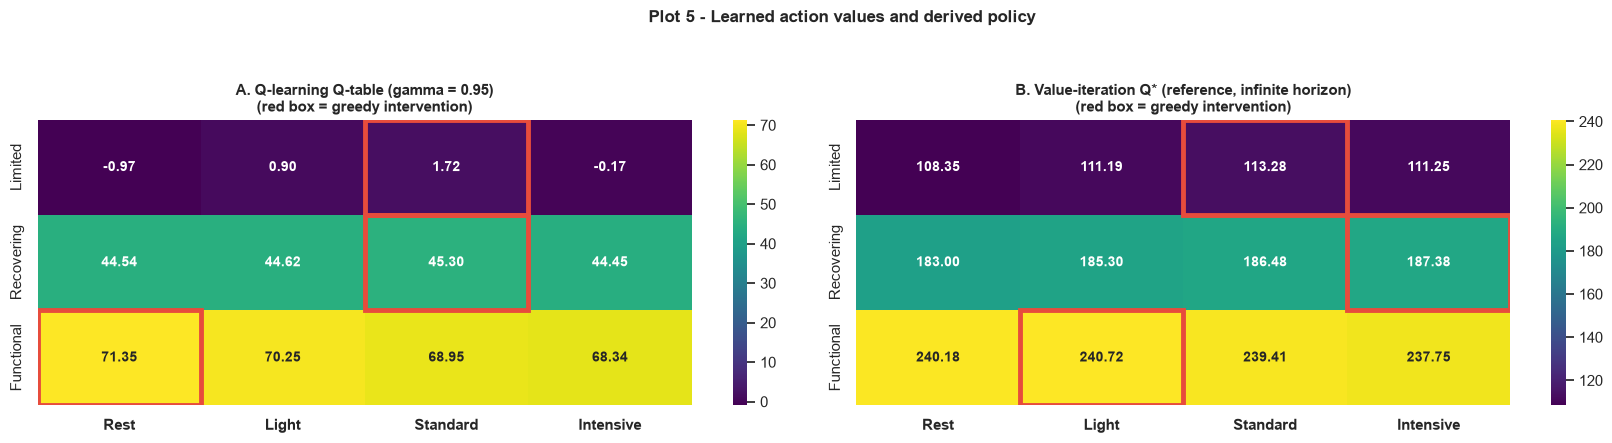

In [8]:
# Plot 5: learned Q-table vs value-iteration reference
fig, axes = plt.subplots(1, 2, figsize=(17, 4.2))
for ax, M, title in [(axes[0], Q, "A. Q-learning Q-table (gamma = 0.95)"),
                     (axes[1], Q_vi, "B. Value-iteration Q* (reference, infinite horizon)")]:
    sns.heatmap(pd.DataFrame(M, index=STATES, columns=ACTION_SHORT), annot=True, fmt=".2f", cmap="viridis", ax=ax,
                annot_kws={"size": 10, "weight": "bold"})
    for i in range(N_STATES):
        ax.add_patch(plt.Rectangle((int(M[i].argmax()), i), 1, 1, fill=False, edgecolor="#E74C3C", lw=3.5))
    ax.set_title(title + "\n(red box = greedy intervention)", fontsize=11, fontweight="bold")
    ax.set_xticklabels(ACTION_SHORT, rotation=0, fontweight="bold")
plt.suptitle("Plot 5 - Learned action values and derived policy", fontsize=12, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

**Learned Q-table and policy (γ = 0.95; Plots 4 and 5).**

| State | Preferred intervention | Q of best | Margin over 2nd best | Immediate-reward best |
|---|---|---|---|---|
| Limited | **Standard Therapy** | 1.72 | 0.82 (vs Light) | Rest |
| Recovering | **Standard Therapy** | 45.30 | 0.68 (vs Light) | Rest |
| Functional | **Rest/Recovery** | 71.35 | 1.10 (vs Light) | Rest |

*Rehabilitation interpretation.* While the patient is Limited or Recovering, the agent accepts a lower immediate utility (Standard Therapy is 1.33 and 1.64 points below Rest) because it increases the chance of progressing to a better state and, in Recovering, reduces the risk of a setback. Once the patient is Functional, the goal has been reached, and the agent minimises the burden of rehabilitation by choosing Rest/Recovery.

*Convergence.* The moving-average training return rises from about 25 (almost random actions while ε is large) to about 40 once ε reaches 0.05, and all Q-values are stable after roughly 40,000 episodes (Plot 4). Every state–intervention pair was updated at least 25,865 times.

*Robustness.* With the decreasing step size, all 5 seeds agree on **Standard Therapy in Limited** and **Rest/Recovery in Functional**. In Recovering, 3 seeds choose Standard and 2 choose Intensive Therapy, because the four Q-values of Recovering lie within 0.84 of each other. With a constant $\alpha = 0.05$, the 5 seeds produce 4 different policies (exact returns between 33.5 and 42.9): the constant step size keeps reacting to the noise of individual targets. This justifies the decreasing step size.

*Comparison with exact references.* The value-iteration policy is **Standard / Intensive / Light**. It is also the best of all 64 stationary policies for the 13-week objective (exact return 42.89). The Q-learning policy ranks **4th of 64** (40.45, i.e. 5.7% lower), and it differs in Recovering (Standard instead of Intensive) and Functional (Rest instead of Light). The values themselves differ much more (e.g. 1.72 vs 113.28 in Limited), because value iteration assumes an infinite horizon, whereas every Q-learning episode ends after 13 weeks.

*Why Q-learning deviates.* The state contains the recovery level but **not the week**, while the episode always ends after 13 decisions. Q-learning averages the targets of all weeks in which a state is visited, and in the final week the target is the immediate reward only (no future term). Functional is reached late: its mean week of visit is 8.3, and 52.6% of its visits fall in weeks 9–12. Recovering is visited on average in week 6.2 (30.5% of visits in weeks 9–12). Near the end of the episode, preventing a setback or promoting progress has little time left to pay off, so cheaper interventions really are better there. Section 4.2 confirms this with the exact time-dependent optimum. Q-learning therefore learns a compromise that fits these late visits, whereas value iteration assumes the future always matters.

### 2.3 Effect of the discount factor $\gamma$

We retrain Q-learning (same $\alpha$, $\epsilon$ schedule and number of episodes) for $\gamma \in \{0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99\}$. For each $\gamma$ we report the greedy policy, the value-iteration policy for the same $\gamma$, and the **undiscounted** 13-week return of the greedy policy (simulated over 1,000 episodes and computed exactly), which is the quantity used to compare policies in Task 3.

,gamma,Q-learning: Limited,Q-learning: Recovering,Q-learning: Functional,Value-iteration policy,Mean 13-week return,Exact 13-week return,SD return
0,0.0000,Rest/Recovery,Rest/Recovery,Rest/Recovery,Rest / Rest / Rest,7.9716,9.4125,67.2995
1,0.3000,Rest/Recovery,Rest/Recovery,Rest/Recovery,Rest / Rest / Rest,7.9716,9.4125,67.2995
2,0.5000,Light Exercise,Rest/Recovery,Rest/Recovery,Light / Rest / Rest,18.6434,20.5217,64.0087
3,0.7000,Light Exercise,Light Exercise,Rest/Recovery,Light / Light / Rest,28.5841,30.1466,69.2074
4,0.8000,Light Exercise,Light Exercise,Rest/Recovery,Standard / Standard / Rest,28.5841,30.1466,69.2074
5,0.9000,Standard Therapy,Standard Therapy,Rest/Recovery,Standard / Intensive / Light,38.0083,40.4462,70.9186
6,0.9500,Standard Therapy,Standard Therapy,Rest/Recovery,Standard / Intensive / Light,38.0083,40.4462,70.9186
7,0.9900,Standard Therapy,Standard Therapy,Rest/Recovery,Standard / Intensive / Light,38.0083,40.4462,70.9186


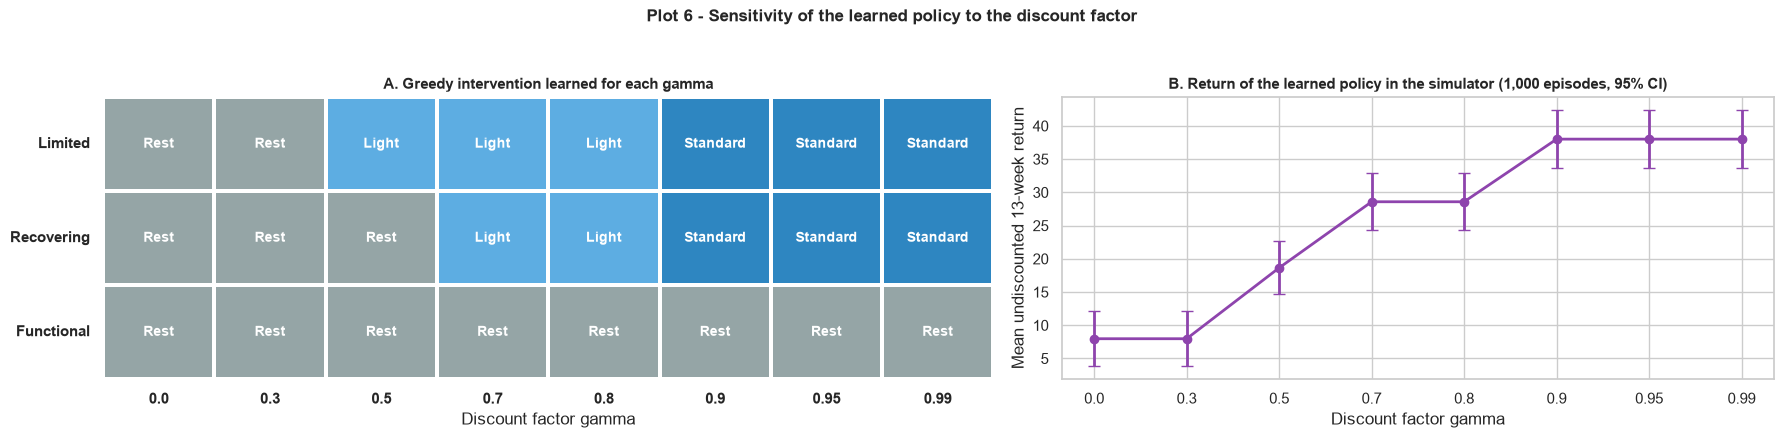

In [9]:
GAMMAS = [0.0, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
gamma_rows, gamma_policies = [], {}


def greedy_policy(s, Q=None, rng=None):
    return int(np.argmax(Q[s]))


for g in GAMMAS:
    Q_g = q_learning(RehabilitationEnv(pi, trans_mat, r_sa, seed=RANDOM_STATE), gamma=g, seed=RANDOM_STATE)[0]
    pol = Q_g.argmax(axis=1)
    pol_vi = value_iteration(trans_mat, r_sa, g).argmax(axis=1)
    gamma_policies[g] = pol
    ret = evaluate_policy(RehabilitationEnv(pi, trans_mat, r_sa, seed=0), greedy_policy, Q=Q_g)
    gamma_rows.append({
        "gamma": g,
        **{f"Q-learning: {s}": ACTIONS[a] for s, a in zip(STATES, pol)},
        "Value-iteration policy": policy_name(pol_vi),
        "Mean 13-week return": ret.mean(),
        "Exact 13-week return": exact_return(pol),
        "SD return": ret.std(),
    })
gamma_df = pd.DataFrame(gamma_rows)
display(gamma_df)

# Plot 6
fig, axes = plt.subplots(1, 2, figsize=(18, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
pol_mat = np.array([gamma_policies[g] for g in GAMMAS]).T
from matplotlib.colors import ListedColormap
sns.heatmap(pol_mat, cmap=ListedColormap(ACTION_COLORS), vmin=-0.5, vmax=3.5, ax=axes[0], cbar=False,
            annot=np.array([[ACTION_SHORT[a] for a in row] for row in pol_mat]), fmt="",
            annot_kws={"size": 10, "weight": "bold", "color": "white"}, linewidths=1.5, linecolor="white")
axes[0].set_xticklabels([str(g) for g in GAMMAS], fontweight="bold")
axes[0].set_yticklabels(STATES, rotation=0, fontweight="bold")
axes[0].set_xlabel("Discount factor gamma")
axes[0].set_title("A. Greedy intervention learned for each gamma", fontsize=11, fontweight="bold")
axes[1].errorbar([str(g) for g in GAMMAS], gamma_df["Mean 13-week return"],
                 yerr=1.96 * gamma_df["SD return"] / np.sqrt(1000), fmt="-o", color="#8E44AD", lw=2, capsize=4)
axes[1].set_xlabel("Discount factor gamma")
axes[1].set_ylabel("Mean undiscounted 13-week return")
axes[1].set_title("B. Return of the learned policy in the simulator (1,000 episodes, 95% CI)", fontsize=11, fontweight="bold")
plt.suptitle("Plot 6 - Sensitivity of the learned policy to the discount factor", fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

**Effect of γ (Plot 6).**

* **γ = 0 and 0.3:** Rest/Recovery in every state. This is the myopic policy, which only maximises the immediate utility. Its 13-week return is the lowest (simulated 7.97, exact 9.41).
* **γ = 0.5:** the agent switches to Light Exercise in Limited first (return 18.6). In Limited the immediate cost of a more active intervention is smallest (−0.31 for Light) and the gain from leaving the worst state is largest.
* **γ = 0.7–0.8:** Light Exercise in both Limited and Recovering (return 28.6).
* **γ ≥ 0.9:** Standard Therapy in Limited and Recovering (return 38.0, exact 40.45). The policy no longer changes between 0.9 and 0.99.
* For every γ the agent rests in Functional. Value iteration switches to Light Exercise in Functional for γ ≥ 0.9, for the time-related reason explained above.

As γ increases, the agent increasingly accepts short-term burden (lower utility now) in exchange for a higher probability of reaching and staying in better states. Since policies are evaluated by the **undiscounted** cumulative utility over 13 weeks, the return of the learned policy grows almost monotonically with γ, from 8.0 to 38.0. A short-sighted agent optimises an objective that does not match the long-term goal of rehabilitation. On the other hand, a very large γ does not help further, because the episode only lasts 13 weeks.

---
## Task 3: Baseline Comparison

We compare the learned Q-learning policy ($\gamma = 0.95$) with the two required baselines and, as additional references, with two further policies:

* **Random policy:** each intervention with probability 1/4.
* **Heuristic policy:** a simple, data-agnostic rule of thumb that matches therapy intensity to the patient's condition:
  * `Limited` → **Light Exercise**: gentle mobilisation while mobility is low and pain is high, avoiding overload but also avoiding complete inactivity;
  * `Recovering` → **Standard Therapy**: progressive loading once the patient tolerates exercise, to push towards full function;
  * `Functional` → **Light Exercise**: maintenance of the recovered function with low burden.
* *(extra)* **Myopic policy:** always choose the intervention with the highest immediate reward $r(s,a)$ (equivalent to Q-learning with $\gamma = 0$).
* *(extra)* **Clinicians' behaviour policy:** the empirical $P(a \mid s)$ observed in the data (Plot 2B).
* *(extra)* **Model-based optimum:** the value-iteration policy for $\gamma = 0.95$, which is also the best of the 64 stationary policies (Section 2.2). It shows how much is lost by learning from samples with a time-agnostic Q-function.

All policies are evaluated with the provided `evaluate_policy` function over 1,000 episodes. Each policy gets a **fresh simulator with the same seed**, so that all policies are evaluated on the same sequence of random initial states (common random numbers).

In [10]:
HEURISTIC = {S_IDX["Limited"]: A_IDX["Light Exercise"],
             S_IDX["Recovering"]: A_IDX["Standard Therapy"],
             S_IDX["Functional"]: A_IDX["Light Exercise"]}
MYOPIC = r_sa.argmax(axis=1)


def random_policy(s, Q=None, rng=None):
    return int(rng.integers(N_ACTIONS))


def heuristic_policy(s, Q=None, rng=None):
    return HEURISTIC[s]


def myopic_policy(s, Q=None, rng=None):
    return int(MYOPIC[s])


def model_based_policy(s, Q=None, rng=None):
    return int(policy_vi[s])


def evaluate_with_trace(policy_fn, Q=None, episodes=1000, seed=0):
    """Same evaluation as evaluate_policy, but also records the actions taken and the states visited."""
    env_e = RehabilitationEnv(pi, trans_mat, r_sa, seed=seed)
    rng = np.random.default_rng(seed)
    returns, actions, states = [], [], []
    for _ in range(episodes):
        s, G = env_e.reset(), 0.0
        for t in range(env_e.horizon):
            a = policy_fn(s, Q=Q, rng=rng)
            states.append(s)
            actions.append(a)
            s, r, done, _ = env_e.step(a)
            G += r
            if done:
                break
        returns.append(G)
    return np.array(returns), np.array(actions), np.array(states)


policies = {
    "Random": (random_policy, None),
    "Heuristic": (heuristic_policy, None),
    "Q-learning (gamma=0.95)": (greedy_policy, Q),
    "Myopic (max r(s,a))": (myopic_policy, None),
    "Clinicians (behaviour)": (behaviour_policy, None),
    "Model-based optimum (VI)": (model_based_policy, None),
}

results, traces = {}, {}
for name, (fn, Qp) in policies.items():
    ret_official = evaluate_policy(RehabilitationEnv(pi, trans_mat, r_sa, seed=0), fn, Q=Qp, episodes=1000, seed=0)
    ret, acts, sts = evaluate_with_trace(fn, Q=Qp, episodes=1000, seed=0)
    assert np.allclose(ret, ret_official)
    results[name] = ret_official
    traces[name] = (acts, sts)

summary_rows = []
for name, ret in results.items():
    acts, sts = traces[name]
    summary_rows.append({
        "Policy": name,
        "Mean cumulative reward": ret.mean(),
        "95% CI half-width": 1.96 * ret.std(ddof=1) / np.sqrt(len(ret)),
        "Average reward per week": ret.mean() / 13,
        "SD of returns": ret.std(ddof=1),
        "5th pct": np.percentile(ret, 5),
        "Median": np.median(ret),
        "95th pct": np.percentile(ret, 95),
        "% weeks Functional": (sts == S_IDX["Functional"]).mean() * 100,
        "% weeks Limited": (sts == S_IDX["Limited"]).mean() * 100,
    })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

action_freq = pd.DataFrame({name: np.bincount(traces[name][0], minlength=N_ACTIONS) / len(traces[name][0])
                            for name in policies}, index=ACTIONS).T
print("Share of weeks in which each intervention is selected:")
display(action_freq)

q_ret, h_ret = results["Q-learning (gamma=0.95)"], results["Heuristic"]
paired = q_ret - h_ret
t_stat, p_val = stats.ttest_rel(q_ret, h_ret)
print(f"Q-learning minus Heuristic (paired, same initial states): mean difference = {paired.mean():+.2f} "
      f"(95% CI {paired.mean() - 1.96 * paired.std(ddof=1) / np.sqrt(len(paired)):+.2f} to "
      f"{paired.mean() + 1.96 * paired.std(ddof=1) / np.sqrt(len(paired)):+.2f}), paired t-test p = {p_val:.2e}")

,Policy,Mean cumulative reward,95% CI half-width,Average reward per week,SD of returns,5th pct,Median,95th pct,% weeks Functional,% weeks Limited
0,Random,24.5676,4.2999,1.8898,69.3753,-87.9175,31.1641,140.0752,21.9692,34.1385
1,Heuristic,32.2222,4.5172,2.4786,72.8805,-81.8836,36.0469,147.8610,25.1538,33.7154
2,Q-learning (gamma=0.95),38.0083,4.3978,2.9237,70.9541,-95.1709,36.0469,153.0433,25.1077,27.6077
3,"Myopic (max r(s,a))",7.9716,4.1734,0.6132,67.3332,-77.8582,5.3933,127.8114,9.1692,45.4154
4,Clinicians (behaviour),28.6313,4.4020,2.2024,71.0214,-86.1094,32.0938,143.4538,24.7846,33.4077
5,Model-based optimum (VI),41.9155,4.5486,3.2243,73.3873,-95.1709,42.9608,154.1935,33.9231,27.1846


Share of weeks in which each intervention is selected:


,Rest/Recovery,Light Exercise,Standard Therapy,Intensive Therapy
Random,0.2529,0.2427,0.2527,0.2517
Heuristic,0.0000,0.5887,0.4113,0.0000
Q-learning (gamma=0.95),0.2511,0.0000,0.7489,0.0000
"Myopic (max r(s,a))",1.0000,0.0000,0.0000,0.0000
Clinicians (behaviour),0.1592,0.3159,0.3582,0.1666
Model-based optimum (VI),0.0000,0.3392,0.2718,0.3889


Q-learning minus Heuristic (paired, same initial states): mean difference = +5.79 (95% CI +4.00 to +7.58), paired t-test p = 3.53e-10


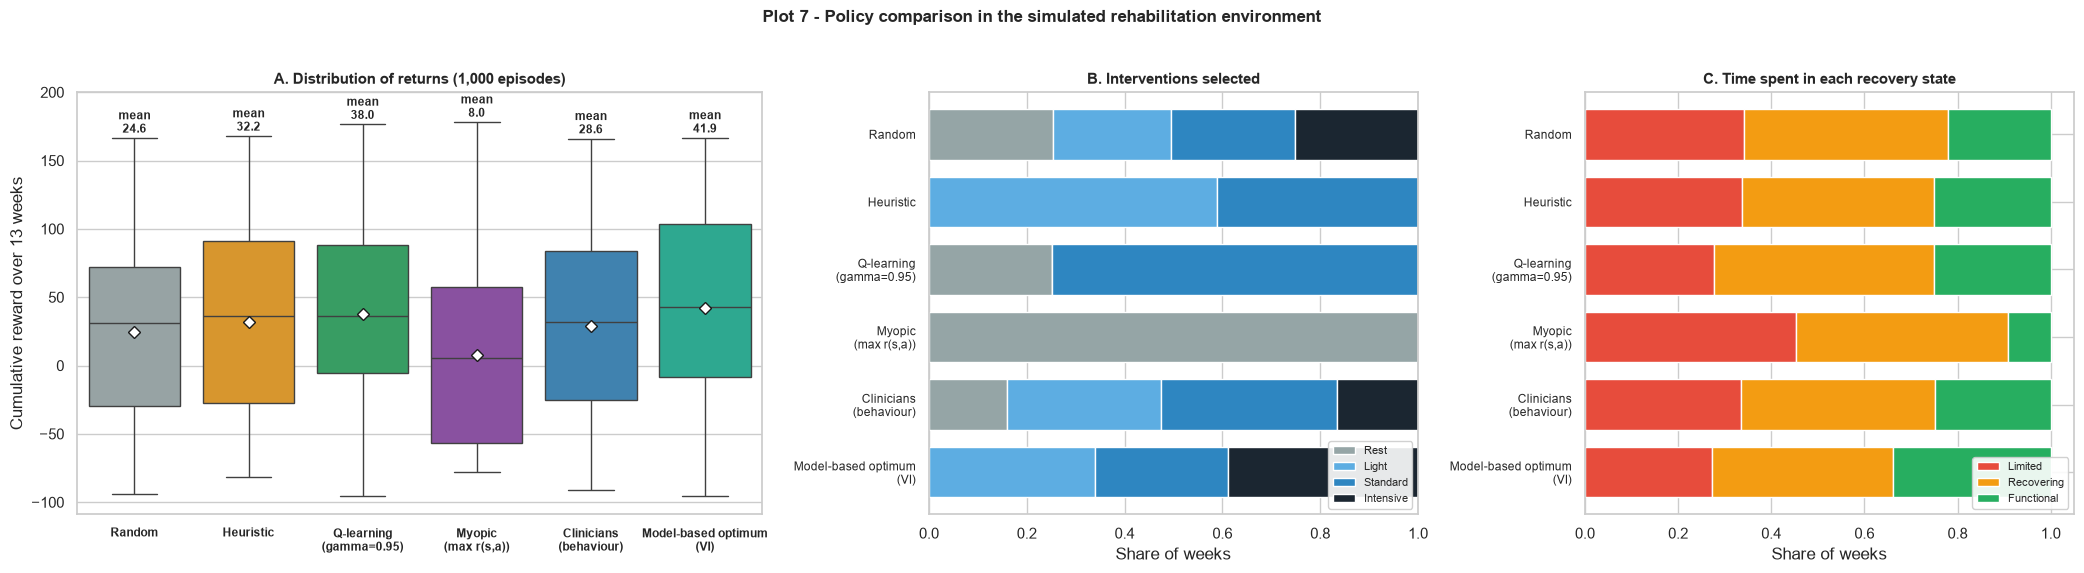

In [11]:
# Plot 7: return distributions, interventions selected and time spent in each state
order_names = list(policies.keys())
pal = ["#95A5A6", "#F39C12", "#27AE60", "#8E44AD", "#2E86C1", "#1ABC9C"]
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})

sns.boxplot(data=pd.DataFrame(results)[order_names], ax=axes[0], palette=pal, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "k"})
for i, name in enumerate(order_names):
    axes[0].text(i, results[name].max() + 4, f"mean\n{results[name].mean():.1f}", ha="center", fontsize=8.5, fontweight="bold")
axes[0].set_xticklabels([n.replace(" (", "\n(") for n in order_names], fontsize=8.5, fontweight="bold")
axes[0].set_ylabel("Cumulative reward over 13 weeks")
axes[0].set_ylim(top=max(r.max() for r in results.values()) + 22)
axes[0].set_title("A. Distribution of returns (1,000 episodes)", fontsize=11, fontweight="bold")

action_freq[ACTIONS].plot(kind="barh", stacked=True, ax=axes[1], color=ACTION_COLORS, width=0.75, edgecolor="white")
axes[1].set_yticklabels([n.replace(" (", "\n(") for n in order_names], fontsize=8.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Share of weeks")
axes[1].legend(ACTION_SHORT, fontsize=8, loc="lower right", framealpha=0.9)
axes[1].set_title("B. Interventions selected", fontsize=11, fontweight="bold")

occ = pd.DataFrame({name: np.bincount(traces[name][1], minlength=N_STATES) / len(traces[name][1]) for name in order_names},
                   index=STATES).T
occ.plot(kind="barh", stacked=True, ax=axes[2], color=[STATE_COLORS[s] for s in STATES], width=0.75, edgecolor="white")
axes[2].set_yticklabels([n.replace(" (", "\n(") for n in order_names], fontsize=8.5)
axes[2].invert_yaxis()
axes[2].set_xlabel("Share of weeks")
axes[2].legend(fontsize=8, loc="lower right", framealpha=0.9)
axes[2].set_title("C. Time spent in each recovery state", fontsize=11, fontweight="bold")
plt.suptitle("Plot 7 - Policy comparison in the simulated rehabilitation environment", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Comparison of the policies (Plot 7).**

| Policy | Mean return (95% CI) | Avg reward / week | SD | % weeks Functional | % weeks Limited |
|---|---|---|---|---|---|
| Random | 24.6 (±4.3) | 1.89 | 69.4 | 22.0 | 34.1 |
| Heuristic | 32.2 (±4.5) | 2.48 | 72.9 | 25.2 | 33.7 |
| **Q-learning (γ=0.95)** | **38.0 (±4.4)** | **2.92** | 71.0 | 25.1 | 27.6 |
| Myopic | 8.0 (±4.2) | 0.61 | 67.3 | 9.2 | 45.4 |
| Clinicians | 28.6 (±4.4) | 2.20 | 71.0 | 24.8 | 33.4 |
| Model-based optimum | 41.9 (±4.5) | 3.22 | 73.4 | 33.9 | 27.2 |

* **Cumulative and average reward:** Q-learning outperforms both required baselines: by 13.4 points over the random policy and **5.8 points over the heuristic**. The paired comparison on the same simulated initial states gives a 95% CI of +4.0 to +7.6 and p = 3.5·10⁻¹⁰, so the difference is clear even though the individual confidence intervals overlap. Q-learning also beats the clinicians' behaviour policy (28.6) and is about 4 points below the model-based optimum (41.9). The myopic policy is by far the worst (8.0), even worse than random.
* **Variability:** the spread of returns is large and similar for all policies (SD 67–73; 5th percentiles between −78 and −95). It is driven mainly by chance (starting in Limited or Recovering and the random transitions), not by the policy. Q-learning and the model-based optimum have slightly wider distributions: active therapy produces more successful recoveries, but patients who remain Limited accumulate its extra burden every week.
* **Interventions selected:** Q-learning uses only two interventions: Standard Therapy (74.9% of weeks, in Limited and Recovering) and Rest/Recovery (25.1%, in Functional). It never selects Light Exercise or Intensive Therapy. The heuristic uses Light (58.9%) and Standard (41.1%), the myopic policy only Rest, and the clinicians a mixture of all four. The model-based optimum never rests, using Light, Standard and Intensive.
* **Where the gain comes from:** Q-learning and the heuristic spend almost the same share of weeks in Functional (25.1% vs 25.2%), but Q-learning spends much less time in Limited (27.6% vs 33.7%) because it uses Standard Therapy instead of Light Exercise in that state. It then collects the higher immediate reward of Rest once Functional. The model-based optimum additionally pushes Recovering patients to Functional faster with Intensive Therapy (33.9% of weeks Functional).

---
## Task 4: Policy Analysis

### 4.1 Immediate reward vs long-term value

For every state we decompose the value-iteration action values ($\gamma = 0.95$) into the **immediate reward** $r(s,a)$ and the **discounted future value** $\gamma \sum_{s'} P(s' \mid s,a) V^*(s')$, both expressed relative to the myopic choice `Rest/Recovery`. This shows directly *why* the learned policy may prefer an intervention with a lower immediate reward.

,State,Intervention,"Immediate r(s,a)",Future value,"Q*(s,a)",Immediate vs Rest,Future vs Rest,Net vs Rest,Chosen
0,Limited,Rest/Recovery,-5.9891,114.3361,108.3470,0.0000,0.0000,0.0000,
1,Limited,Light Exercise,-6.2987,117.4879,111.1892,-0.3096,3.1518,2.8421,
2,Limited,Standard Therapy,-7.3208,120.5960,113.2752,-1.3317,6.2599,4.9281,<== best
3,Limited,Intensive Therapy,-7.4944,118.7439,111.2495,-1.5053,4.4078,2.9025,
4,Recovering,Rest/Recovery,4.4173,178.5824,182.9998,0.0000,0.0000,0.0000,
5,Recovering,Light Exercise,3.9034,181.3961,185.2994,-0.5140,2.8137,2.2997,
6,Recovering,Standard Therapy,2.7728,183.7044,186.4773,-1.6445,5.1220,3.4775,
7,Recovering,Intensive Therapy,1.4033,185.9786,187.3819,-3.0141,7.3962,4.3821,<== best
8,Functional,Rest/Recovery,14.4725,225.7118,240.1842,0.0000,0.0000,0.0000,
9,Functional,Light Exercise,13.7624,226.9618,240.7243,-0.7100,1.2501,0.5400,<== best


V*(s) = {'Limited': np.float64(113.28), 'Recovering': np.float64(187.38), 'Functional': np.float64(240.72)}


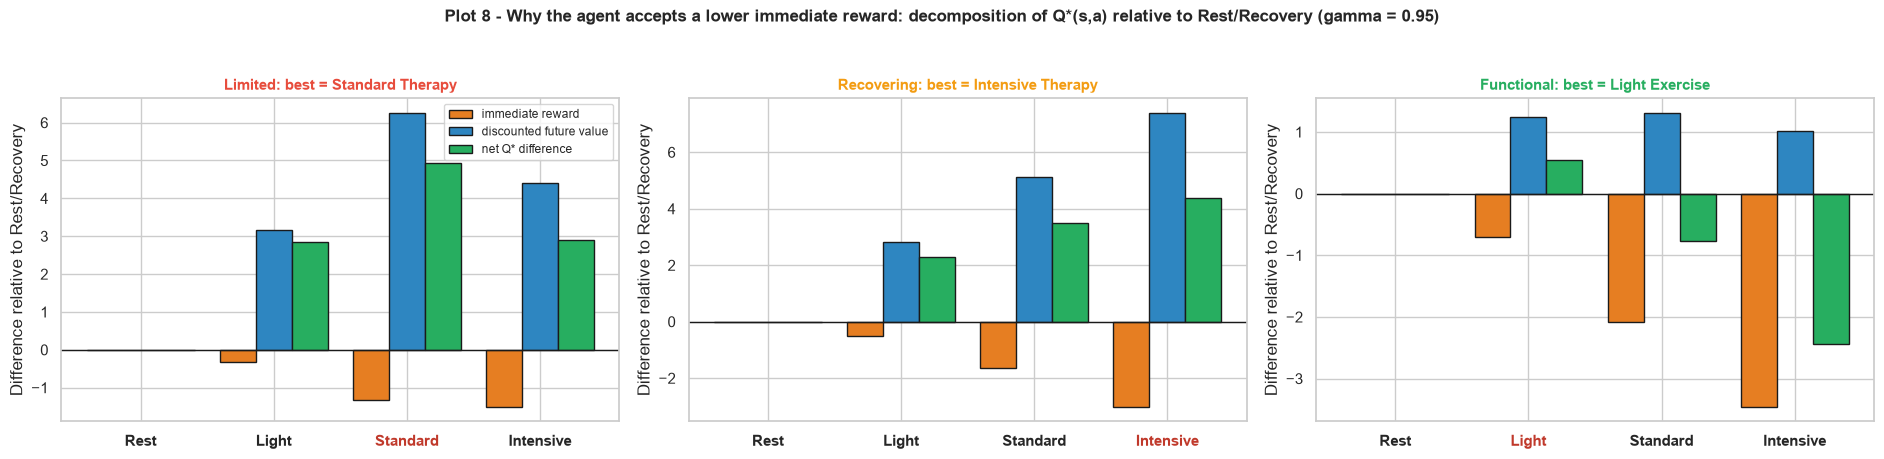

In [12]:
V_star = Q_vi.max(axis=1)
dec_rows = []
for i, s in enumerate(STATES):
    for j, a in enumerate(ACTIONS):
        fut = GAMMA * trans_mat[i, j] @ V_star
        fut_rest = GAMMA * trans_mat[i, 0] @ V_star
        dec_rows.append({
            "State": s, "Intervention": a,
            "Immediate r(s,a)": r_sa[i, j],
            "Future value": fut,
            "Q*(s,a)": Q_vi[i, j],
            "Immediate vs Rest": r_sa[i, j] - r_sa[i, 0],
            "Future vs Rest": fut - fut_rest,
            "Net vs Rest": Q_vi[i, j] - Q_vi[i, 0],
            "Chosen": "<== best" if j == policy_vi[i] else "",
        })
dec_df = pd.DataFrame(dec_rows)
display(dec_df)
print(f"V*(s) = {dict(zip(STATES, V_star.round(2)))}")

# Plot 8
fig, axes = plt.subplots(1, 3, figsize=(19, 4.4), sharey=False)
for i, s in enumerate(STATES):
    sub = dec_df[dec_df["State"] == s]
    x = np.arange(N_ACTIONS)
    axes[i].bar(x - 0.27, sub["Immediate vs Rest"], 0.27, color="#E67E22", edgecolor="k", label="immediate reward")
    axes[i].bar(x, sub["Future vs Rest"], 0.27, color="#2E86C1", edgecolor="k", label="discounted future value")
    axes[i].bar(x + 0.27, sub["Net vs Rest"], 0.27, color="#27AE60", edgecolor="k", label="net Q* difference")
    axes[i].axhline(0, color="k", lw=1)
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(ACTION_SHORT, fontweight="bold")
    best = int(policy_vi[i])
    axes[i].get_xticklabels()[best].set_color("#C0392B")
    axes[i].set_title(f"{s}: best = {ACTIONS[best]}", fontsize=11, fontweight="bold", color=STATE_COLORS[s])
    axes[i].set_ylabel("Difference relative to Rest/Recovery")
axes[0].legend(fontsize=8.5)
plt.suptitle("Plot 8 - Why the agent accepts a lower immediate reward: decomposition of Q*(s,a) relative to Rest/Recovery (gamma = 0.95)",
             fontsize=12, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

### 4.2 How robust is the policy to uncertainty in the estimated environment?

The transition probabilities and rewards are estimated from a finite set of patients, and some of the differences between interventions are small. To see how much the recommended policy depends on this sampling noise, we draw **200 bootstrap samples of patients** (with replacement), re-estimate $(P, R)$ from each sample, and recompute the optimal policy for several values of $\gamma$. Value iteration is used so that the analysis is not affected by Q-learning's own randomness.

We also look at the role of **time**. The environment state does not include the week, but the episode has a fixed length of 13 weeks. The exact optimal policy for the *undiscounted* 13-week objective is therefore time-dependent, and we compute it by backward induction over the remaining weeks.

Share of 200 bootstrap re-estimations of the environment in which each intervention is optimal:


,gamma,State,Rest,Light,Standard,Intensive,Point-estimate choice
0,0.5000,Limited,0.2350,0.7650,0.0000,0.0000,Light Exercise
1,0.5000,Recovering,0.5550,0.4450,0.0000,0.0000,Rest/Recovery
2,0.5000,Functional,0.9850,0.0150,0.0000,0.0000,Rest/Recovery
3,0.9000,Limited,0.0000,0.0000,0.9850,0.0150,Standard Therapy
4,0.9000,Recovering,0.0000,0.0000,0.0650,0.9350,Intensive Therapy
5,0.9000,Functional,0.2500,0.7500,0.0000,0.0000,Light Exercise
6,0.9500,Limited,0.0000,0.0000,0.9750,0.0250,Standard Therapy
7,0.9500,Recovering,0.0000,0.0000,0.0050,0.9950,Intensive Therapy
8,0.9500,Functional,0.1350,0.8650,0.0000,0.0000,Light Exercise
9,0.9900,Limited,0.0000,0.0000,0.9750,0.0250,Standard Therapy


Exact optimal time-dependent policy for the undiscounted 13-week return:


,week 0 (13 left),week 1 (12 left),week 2 (11 left),week 3 (10 left),week 4 (9 left),week 5 (8 left),week 6 (7 left),week 7 (6 left),week 8 (5 left),week 9 (4 left),week 10 (3 left),week 11 (2 left),week 12 (1 left)
Limited,Standard,Standard,Standard,Standard,Standard,Standard,Standard,Standard,Standard,Standard,Light,Light,Rest
Recovering,Intensive,Intensive,Intensive,Intensive,Intensive,Intensive,Intensive,Intensive,Intensive,Standard,Light,Rest,Rest
Functional,Light,Light,Light,Light,Light,Light,Light,Light,Light,Rest,Rest,Rest,Rest


Expected 13-week return: time-dependent optimum = 45.66 (simulated: 44.78) | best stationary policy = 42.89 | Q-learning policy = 40.45


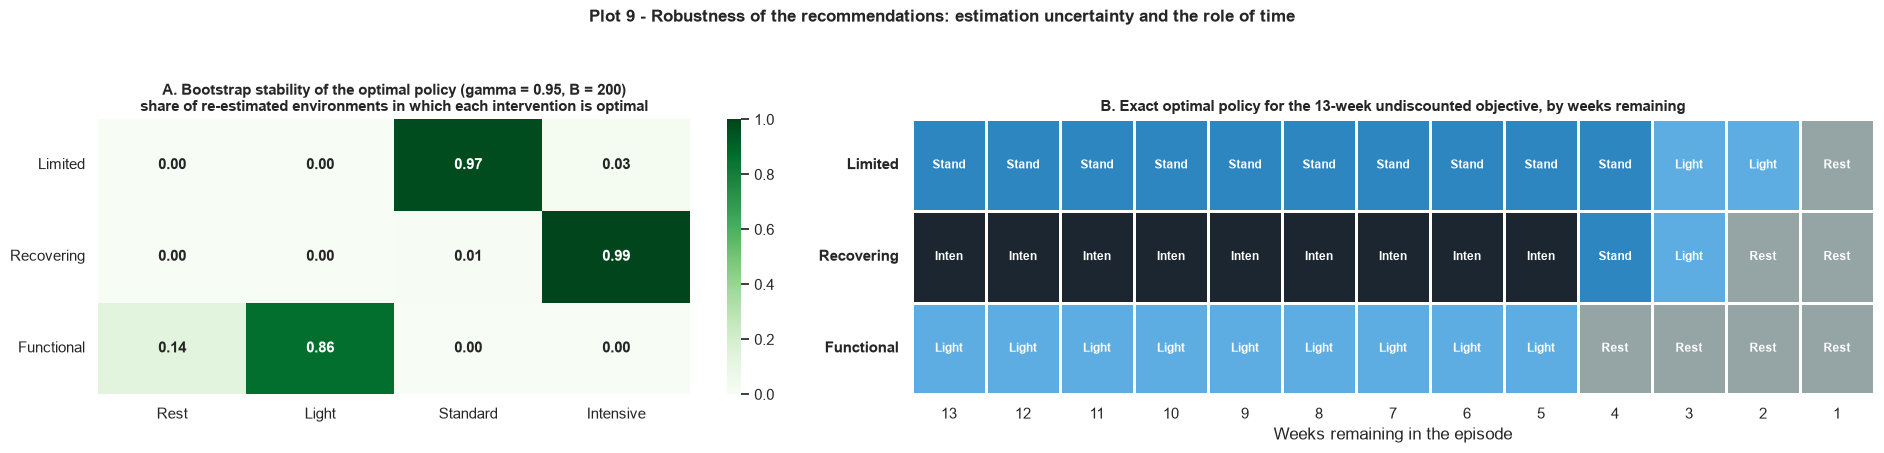

In [13]:
def estimate_env(df):
    tr = df.dropna(subset=["s_next"]).astype({"s_next": int})
    c = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    np.add.at(c, (tr["s"].values, tr["a"].values, tr["s_next"].values), 1)
    P = c / np.maximum(c.sum(axis=2, keepdims=True), 1)
    R = df.groupby(["s", "a"])["utility"].mean().unstack().reindex(index=range(N_STATES), columns=range(N_ACTIONS)).values
    return P, R


rng_b = np.random.default_rng(RANDOM_STATE)
pid_groups = {pid: g for pid, g in rehab.groupby("patient_id")}
pids = np.array(list(pid_groups.keys()))
B = 200
boot_gammas = [0.5, 0.9, 0.95, 0.99]
boot_counts = {g: np.zeros((N_STATES, N_ACTIONS), dtype=int) for g in boot_gammas}
for b in range(B):
    sample = rng_b.choice(pids, size=len(pids), replace=True)
    df_b = pd.concat([pid_groups[p] for p in sample], ignore_index=True)
    P_b, R_b = estimate_env(df_b)
    for g in boot_gammas:
        boot_counts[g][np.arange(N_STATES), value_iteration(P_b, R_b, g).argmax(axis=1)] += 1

boot_rows = []
for g in boot_gammas:
    for i, s in enumerate(STATES):
        boot_rows.append({"gamma": g, "State": s, **{ACTION_SHORT[j]: boot_counts[g][i, j] / B for j in range(N_ACTIONS)},
                          "Point-estimate choice": ACTIONS[int(value_iteration(trans_mat, r_sa, g)[i].argmax())]})
boot_df = pd.DataFrame(boot_rows)
print(f"Share of {B} bootstrap re-estimations of the environment in which each intervention is optimal:")
display(boot_df)

# Finite-horizon (undiscounted, 13 decisions) optimal policy by backward induction
H = 13
V_next = np.zeros(N_STATES)
fh_policy = np.zeros((H, N_STATES), dtype=int)
for t in reversed(range(H)):
    Q_t = r_sa + trans_mat @ V_next
    fh_policy[t] = Q_t.argmax(axis=1)
    V_next = Q_t.max(axis=1)
fh_value = pi @ V_next
fh_df = pd.DataFrame([[ACTION_SHORT[a] for a in fh_policy[t]] for t in range(H)], columns=STATES,
                     index=[f"week {t} ({H - t} left)" for t in range(H)]).T
print("Exact optimal time-dependent policy for the undiscounted 13-week return:")
display(fh_df)


def time_aware_policy_factory(env_obj):
    def pol(s, Q=None, rng=None):
        return int(fh_policy[env_obj.t, s])
    return pol


env_fh = RehabilitationEnv(pi, trans_mat, r_sa, seed=0)
fh_ret = evaluate_policy(env_fh, time_aware_policy_factory(env_fh), episodes=1000, seed=0)
print(f"Expected 13-week return: time-dependent optimum = {fh_value:.2f} (simulated: {fh_ret.mean():.2f}) | "
      f"best stationary policy = {enum_df.iloc[0, 1]:.2f} | Q-learning policy = {exact_return(policy_q):.2f}")

# Plot 9
fig, axes = plt.subplots(1, 2, figsize=(19, 4.3), gridspec_kw={"width_ratios": [1, 1.3]})
g_show = 0.95
sns.heatmap(pd.DataFrame(boot_counts[g_show] / B, index=STATES, columns=ACTION_SHORT), annot=True, fmt=".2f",
            cmap="Greens", vmin=0, vmax=1, ax=axes[0], annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title(f"A. Bootstrap stability of the optimal policy (gamma = {g_show}, B = {B})\n"
                  "share of re-estimated environments in which each intervention is optimal", fontsize=10.5, fontweight="bold")
axes[0].set_yticklabels(STATES, rotation=0)
sns.heatmap(fh_policy.T, cmap=ListedColormap(ACTION_COLORS), vmin=-0.5, vmax=3.5, cbar=False, ax=axes[1],
            annot=np.array([[ACTION_SHORT[a][:5] for a in row] for row in fh_policy.T]), fmt="",
            annot_kws={"size": 8.5, "weight": "bold", "color": "white"}, linewidths=1, linecolor="white")
axes[1].set_xticklabels([str(H - t) for t in range(H)])
axes[1].set_xlabel("Weeks remaining in the episode")
axes[1].set_yticklabels(STATES, rotation=0, fontweight="bold")
axes[1].set_title("B. Exact optimal policy for the 13-week undiscounted objective, by weeks remaining",
                  fontsize=10.5, fontweight="bold")
plt.suptitle("Plot 9 - Robustness of the recommendations: estimation uncertainty and the role of time",
             fontsize=12, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

**Preferred interventions.** Q-learning prefers **Standard Therapy** in Limited and Recovering and **Rest/Recovery** in Functional. The model-based optimum prefers Standard / **Intensive** / **Light**.

**Rarely selected interventions.** The learned policy never uses Light Exercise or Intensive Therapy. Intensive Therapy is never the best choice in Limited: it has a lower immediate reward than Standard (−7.49 vs −7.32) *and* a lower improvement probability (0.158 vs 0.184), so it is dominated. In Functional, Standard and Intensive Therapy cost 2.1–3.5 utility points per week for a setback reduction that is no better than Light Exercise.

**Learned policy vs immediate reward.** The reward matrix alone recommends Rest/Recovery in every state. The learned policy departs from it in Limited and Recovering, and the model-based optimum also in Functional.

**Lower immediate reward, higher long-term value (Plot 8).** Relative to Rest/Recovery:
* in **Limited**, Standard Therapy loses 1.33 points now but gains 6.26 points of discounted future value (net +4.93), because it doubles the weekly chance of progressing (0.184 vs 0.096);
* in **Recovering**, Intensive Therapy loses 3.01 points now but gains 7.40 in future value (net +4.38), through more progress (0.165 vs 0.052) and fewer setbacks;
* in **Functional**, Light Exercise loses 0.71 now and gains 1.25 (net +0.54), only by lowering the setback risk from 5.9% to 3.4%. The margin is small, which explains why the choice in Functional is the least stable one.

**Sensitivity to the discount factor.** The policy is very sensitive at low and intermediate γ (Rest → Light → Standard as γ grows, Section 2.3) and stable for γ ≥ 0.9. The bootstrap analysis (Plot 9A) shows that, for γ = 0.95, the model-based recommendations are robust to sampling uncertainty in Limited (Standard in 97.5% of the 200 re-estimated environments) and in Recovering (Intensive in 99.5%). They are less certain in Functional (Light in 86.5%, Rest in 13.5%). At γ = 0.5 the choice in Recovering is almost a coin flip (Rest 55.5%, Light 44.5%).

**Role of time (Plot 9B).** The exact optimal policy for the 13-week objective depends on the number of weeks left. It uses Standard (Limited), Intensive (Recovering) and Light (Functional) for most of the episode, but switches to cheaper interventions in the last 3–4 weeks, and to Rest everywhere in the final week. This happens because the future benefits of therapy no longer have time to materialise. Its expected return (45.66) is higher than that of the best stationary policy (42.89) and of the Q-learning policy (40.45).

**Surprising decisions and possible explanations.**
* *Rest/Recovery for Functional patients* (Q-learning) contradicts the clinical intuition that recovered patients should keep a maintenance programme. It results from the **reward definition**, which penalises burden, so Rest has the highest utility (14.47). It is also a result of the **finite horizon combined with a time-agnostic state**: Functional is mostly visited in the last weeks, where preventing future setbacks has little remaining value.
* *Intensive Therapy for Recovering patients* (model-based optimum) has the lowest immediate utility (1.40) but the best transitions. Clinically it is plausible for patients who tolerate exercise, but risks such as overload or pain flare-ups are only represented through the utility.
* *Standard better than Intensive in Limited* is plausible (overload of very limited patients), but it may also reflect **confounding in the estimated transitions**: Intensive Therapy was rarely given to Limited patients (898 transitions), and probably to a particular subgroup.
* **Stochasticity and noise:** the returns have an SD of about 70, and the Q-values of Recovering differ by less than 1 point, so different seeds choose different interventions in that state (Standard 3/5, Intensive 2/5).
* **Exploration:** with ε-greedy exploration, non-greedy pairs are updated less often (e.g. 25,865 updates for Functional/Intensive vs 282,908 for Limited/Standard), so their estimates are less precise. A constant step size made this noise visible as unstable policies.
* **Limitations of the synthetic environment:** the state does not contain time, baseline risk or history, the transition probabilities are assumed equal for all patients and weeks, and the simulator is more optimistic than the real data (Section 1.3).

**Immediate vs long-term cumulative utility.** Maximising the immediate utility (Rest everywhere) yields only 8.0 points over 13 weeks. Policies that accept a lower utility today in exchange for better transitions reach 38.0 (Q-learning) to 41.9 (model-based optimum), and 45.7 if the timing is also adapted. In rehabilitation the best week-by-week choice is therefore not the best overall strategy.

---
## Task 5: Reflection

**Potential of sequential decision-making.** A sequential approach takes into account that today's intervention changes next week's state and therefore all future outcomes. Choosing each week's intervention independently by its immediate utility (the myopic policy) leads to resting every week: patients stay longer in Limited (45% of weeks) and the cumulative utility collapses to 8.0, compared with 38–42 for long-term policies. RL also makes it possible to adapt the intervention to the current state and, as Plot 9B shows, to the time remaining in the programme.

**Delayed, noisy or proxy rewards.**
* *Delayed:* the benefit of therapy appears only weeks later, through a change of state, so the agent must solve a credit-assignment problem. Learning this requires many episodes and a careful choice of γ.
* *Noisy:* noisy transitions and rewards make the Q-values fluctuate. With a constant learning rate, different seeds gave different policies, and the differences in Recovering remained within the noise.
* *Proxy:* the agent optimises exactly the `utility` formula. Its weighting of burden vs improvement directly determines the policy; for example, Rest in Functional is chosen because of the burden penalty, not because it is clinically best. Real outcomes (pain, function, return to work, re-injury, patient preferences) are multidimensional, and the 13-week horizon ignores what happens after rehabilitation.

**Why the learned policy is not clinical evidence.**
* The simulator is estimated from **observational** trajectories in which clinicians chose the interventions, possibly based on information not in the state (confounding by indication). The associations in $P(s' \mid s,a)$ are therefore not causal effects.
* The agent also applies interventions in situations where clinicians rarely used them (e.g. Intensive Therapy in Limited). This assumes the estimated transitions still hold under this different policy (distribution shift).
* The estimates are uncertain (the bootstrap shows instability in Functional), and the policy is only optimal for the reward we defined, in a simplified synthetic Markov environment that does not even reproduce the data perfectly.
* Clinical evidence would require randomised or prospective studies, or at least careful off-policy evaluation with uncertainty quantification.

**Clinical expertise and RL as complements.** RL can act as a *decision-support* tool. It proposes interventions with their expected long-term value and uncertainty, and it can reveal under-used strategies; for example, the agent uses Standard Therapy in Limited much more often than the clinicians in the data (32%). Clinicians, in turn, define what a good outcome is (the reward), impose safety constraints (e.g. no intensive therapy when pain is high), interpret recommendations in the context of the individual patient, and keep the final decision. Interpretable models such as the 3×4 Q-table make this dialogue possible.

**How a real decision-support problem would differ.**
* *Three recovery states:* real recovery is continuous, multidimensional and **not directly observed**. The state would have to be inferred from noisy measurements (e.g. with the HMM of M5), which turns the problem into a partially observable MDP (POMDP).
* *Four interventions:* real programmes vary in type, dose, frequency and combination, which gives a much larger action space.
* *Utility as reward:* outcomes are multi-objective and patient-specific. The reward would have to be designed with clinicians and patients, possibly with constraints.
* *Small Markov state:* the state would need to include time since injury, baseline risk, comorbidities and treatment history. We saw that even adding the week number improves the optimum from 42.9 to 45.7. Larger state spaces require function approximation (e.g. deep RL).
* *Transitions estimated from synthetic trajectories:* real data are limited, irregular, missing and confounded, so offline RL methods with conservative estimates would be needed.
* *No interaction with real patients:* policies cannot be learned by trial and error on patients. Learning must be offline, evaluation must use off-policy methods and clinical studies, and safety and ethics constrain exploration.

---
## 6. Conclusions

* **Environment (Task 1):** from 39,000 observed transitions we estimated $P(s' \mid s,a)$, $r(s,a)$ and $\pi$. More intensive interventions increase the chance of progress and reduce setbacks, but they have a lower immediate utility. Rest/Recovery has the highest immediate reward in every state. The simulator reproduces the data reasonably well but is somewhat more optimistic.
* **Q-learning (Task 2):** with $\gamma = 0.95$, $\epsilon$ decaying from 1 to 0.05 and a step size $1/N(s,a)^{0.7}$, the agent learns **Standard Therapy in Limited and Recovering and Rest/Recovery in Functional**. A constant step size gave unstable policies. Increasing γ shifts the policy from resting everywhere towards active therapy, and the 13-week return grows from 8.0 to 38.0.
* **Baselines (Task 3):** the learned policy (38.0) clearly outperforms the heuristic (32.2; paired difference +5.8, p < 10⁻⁹), the random policy (24.6), the clinicians' behaviour (28.6) and the myopic policy (8.0). It is close to, but below, the best stationary policy found by dynamic programming (41.9 simulated, 42.9 exact).
* **Policy analysis (Task 4):** therapy is preferred despite its lower immediate reward because of its effect on future states. The remaining gap to the optimum is explained by the time-agnostic state in a fixed 13-week episode, together with small value differences in Recovering and Functional. The recommendations for Limited are robust; those for Functional are the least certain.
* **Reflection (Task 5):** RL captures the trade-off between immediate and long-term utility that weekly decisions miss. However, a policy learned in a simplified, observational and synthetic environment is a hypothesis for clinicians to examine, not evidence of clinical effectiveness.